- 사전분포 p(z): x를 보기 전에 가정한 z에 대한 확률분포. VAE에서는 N(0, I)
- N(0, I): 평균이 영벡터 0이고, 공분산 행렬이 단위행렬 I인 정규분포. 각 차원이 평균 0, 분산 1이고 서로 독립이다.
- 실제 사후분포 p(z|x): x를 본 뒤 z에 대한 분포. 베이즈 정리로 정해지지만, p(x)를 계산할 수 없어서 구할 수 없음.
- 근사 사후분포 q(z|x): x를 본 뒤 z에 대한 분포를 인코더가 근사한 것. N(μ, σ²)
- 가능도 p(x|z): z를 주었을때, x에 대한 분포 (디코더가 사용)
- 재구성 항: q(z|x)에서 뽑은 z로 디코더가 원본 x를 얼마나 잘 복원하는가를 로그 확률로 표현한 값
- μ (mu): 평균. 인코더가 출력한 이미지에 대응하는 잠재공간 위의 중심 위치
- σ (sigma): 표준편차. 평균의 위치에서 z를 뽑는 범위의 폭.
- σ²: 분산
- 재매개변수화 트릭: 정규분포를 따르는 값은 선형변환해도 정규분포를 따르는 성질을 이용한 트릭. 
  - 인코더의 출력 N(μ, σ²)에서 뽑은 샘플은 정규분포 N(0, I)를 따르는 ε 에 σ 를 곱하고 μ 를 더한값과 같은 분포를 따름 (z = μ + σ·ε)
  - 샘플링 지점에서 무작위성을 ε로 분리해서, μ와 σ에 의한 오차의 기울기를 인코더까지 도달하게 하는것이 목적
  - 트릭이 없다면, 재구성에 의한 오차는 보지않고, KL항만 보고 학습해서, 모든 입력에 N(0, I)를 출력하게되고, 잠재변수에는 x의 정보가 남지 않음
- 목적함수 ELBO = 재구성항 E_q - KL
  - 재구성항 E_q: 인코더가 예측한 q(z|x)에서 뽑은 z로 디코더가 복원한 이미지가 원본과 얼마나 가까운가를 로그확률로 표현한값
  - KL은 두 확률분포가 얼마나 다른지를 표현(같으면 0). 여기에서는 근사 사후분포 q(z|x) = N(μ, σ²)와 사전분포 p(z) = N(0, I)의 차이
- 학습
  - 재구성항을 학습하며 x̂, z, μ와 σ를 차례로 거치므로 디코더와 인코더에 모두 기울기를 보냅니다. (L1)
  - KL을 학습하며 μ와 σ만으로 계산하므로 인코더에만 기울기를 보냅니다. (L2)
  - 디코더는 재구성 항으로만 학습하고, 인코더는 두 항이 당기는 방향의 균형으로 학습.
- 생성은 인코더를 사용하는것이 아니라, N(0, I)에서 뽑은 z를 디코더에 넣어서 사용 (torch.randn(sample_size, latent_dim))


- 인코더: 입력을 다른 표현으로 바꾸는 신경망
- 디코더: 학습된 파라미터를 통해, 입력된 다른 표현을 원래 입력과 같은 형태로 바꾸는 신경망
- 오토인코더: 입력 -> 다른 표현 -> 원래 입력으로 출력하도록 학습한 인코더와 디코더의 조합
- 변이형 오토인코더: 인코더의 출력을 특정 지점이 아니라, 입력마다 다른 잠재변수의 분포 N(μ, σ²)로 표현하도록 학습한 오토인코더. 학습할 때 KL 항으로 이 분포들을 N(0, I)에 가깝게 제약한다.
- VAE의 학습 목표는 데이터의 로그 가능도를 최대화 하는것. 가능도 최대화는 학습 데이터가 모델에서 나올 확률이 가장 높아지도록 파라미터를 학습하는 것 (로그를 붙이는 이유는 계산의 편의를 위함). 이 목표는 실제 데이터 분포와 모델 분포 사이의 KL을 최소화하는 것과 같음
- 로그 가능도의 계산은 모든 잠재변수z에 대해 적분해야 하므로, 직접 계산이 어려움. 그래서 계산 가능한 ELBO를 대신 최적화(-ELBO를 손실로 학습진행)



In [ ]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
from torch import nn, optim
from torchvision import datasets, transforms

# 하이퍼 파라미터
input_dim = 784 # 이미지 데이터 x 의 크기 (MNIST는 28 x 28 = 784)
hidden_dim = 200 # 신경망 중간층 차원 수
latent_dim = 20 # 잠재변수 벡터 z의 차원 수

epochs = 30
learning_rate = 3e-4
batch_size = 32

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, hidden_dim)
        self.linear_mu = nn.Linear(hidden_dim, latent_dim)
        self.linear_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        h = self.linear(x)
        h = F.relu(h)
        mu = self.linear_mu(h)
        logvar = self.linear_logvar(h)
        sigma = torch.exp(0.5 * logvar)
        return mu, sigma

class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super().__init__()
        self.linear1 = nn.Linear(latent_dim, hidden_dim)
        self.linear2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):
        h = self.linear1(z)
        h = F.relu(h)
        h = self.linear2(h)
        x_hat = F.sigmoid(h)
        return x_hat

def reparameterize(mu, sigma):
    eps = torch.randn_like(sigma)
    z = mu + eps * sigma
    return z

class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dim, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dim, input_dim)

    def get_loss(self, x):
        mu, sigma = self.encoder(x) # 입력에 대해 출력한 근사 사후분포 q(z|x)의 평균과 표준편차
        z = reparameterize(mu, sigma) # 근사 사후분포로 부터 뽑은 잠재변수 z: 재구성항
        x_hat = self.decoder(z) # 학습된 z의 가능도로 뽑은 x_hat: 재구성항으로 복원

        batch_size = len(x)
        L1 = F.mse_loss(x_hat, x, reduction='sum') # 제곱 오차의 'sum'
        L2 = - torch.sum(1 + torch.log(sigma ** 2) - mu ** 2 - sigma ** 2) # KL 항
        return (L1 + L2) / batch_size # 손실함수의 평균값

# 데이터셋 준비
transform = transforms.Compose([
    transforms.ToTensor(), # 텐서 변환 후
    transforms.Lambda(torch.flatten) # 이미지 평탄화
])

dataset = datasets.MNIST(
    root = './data',
    train=True,
    download=True,
    transform=transform
)
dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True
)

# 모델과 옵티마이저
model = VAE(input_dim, hidden_dim, latent_dim)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)
losses = []

# 학습
for epoch in range(epochs):
    loss_sum = 0.0
    cnt = 0

    for x, label in dataloader:
        optimizer.zero_grad() # 옵티마이저 기울기 초기화
        loss = model.get_loss(x) # VAE 손실함수 계산
        loss.backward() # 역전파
        optimizer.step() # 매개변수 갱신

        loss_sum += loss.item()
        cnt += 1

    loss_avg = loss_sum / cnt
    losses.append(loss_avg)
    print(loss_avg)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.78MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 147kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.98MB/s]


54.13800513305664
45.139173010253906
43.03392182820638
42.048465458170575
41.346174072265626
40.92919632161458
40.60737435506185
40.344667173258465
40.186400345865884
40.02791258544922
39.915061850992835
39.77865835367839
39.660291666666666
39.53333141682943
39.457229137166344
39.36846520996094
39.26872271321614
39.22360531819661
39.15651974690755
39.06410852355957
39.01641617635091
38.956079087320965
38.90003473714193
38.87331111857096
38.795573459879556
38.75806777852376
38.714797467041016
38.6748437479655
38.62353699035644
38.602562172444664


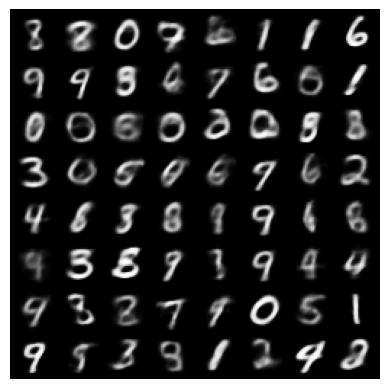

In [2]:
with torch.no_grad():
    sample_size = 64
    z = torch.randn(sample_size, latent_dim)
    x = model.decoder(z)
    generated_images = x.view(sample_size, 1, 28, 28)

grid_img = torchvision.utils.make_grid(
    generated_images,
    nrow=8,
    padding=2,
    normalize=True
)

plt.imshow(grid_img.permute(1, 2, 0))
plt.axis('off')
plt.show()